In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
!mkdir -p ~/.kaggle
!cp /content/kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat '/content/kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
!pip install -q --upgrade kaggle

In [ ]:
!kaggle --version

Kaggle CLI 2.2.5


In [ ]:
!kaggle datasets list -s brats-2021-task1

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, gener

In [ ]:
# Download the dataset first
!kaggle datasets download -d dschettler8845/brats-2021-task1

import zipfile

# Extract the downloaded zip file
with zipfile.ZipFile('/content/brats-2021-task1.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/BraTS2021')

print("Dataset extracted successfully!")

Dataset URL: https://www.kaggle.com/datasets/dschettler8845/brats-2021-task1
License(s): copyright-authors
Resuming from 1129316352 bytes (12065457607 bytes left)...
100% 12.3G/12.3G [02:15<00:00, 88.9MB/s]

Dataset extracted successfully!


In [ ]:
import os

path = "/content/brats-2021-task1.zip"

print("File exists:", os.path.exists(path))

if os.path.exists(path):
    print("File size (GB):", round(os.path.getsize(path) / (1024**3), 2))

File exists: True
File size (GB): 1.05


In [ ]:
import os

path = "/content/BraTS2021"

print("Folder exists:", os.path.exists(path))
print("Number of items:", len(os.listdir(path)))
print("First 10 items:", os.listdir(path)[:10])

Folder exists: True
Number of items: 3
First 10 items: ['BraTS2021_Training_Data.tar', 'BraTS2021_00495.tar', 'BraTS2021_00621.tar']


In [ ]:
import os
import shutil

folder = "/content/BraTS2021"

for file in os.listdir(folder):
    path = os.path.join(folder, file)
    size = os.path.getsize(path) / (1024**3)
    print(file, ":", round(size, 2), "GB")

free_space = shutil.disk_usage("/content").free / (1024**3)
print("\nAvailable storage:", round(free_space, 2), "GB")

BraTS2021_Training_Data.tar : 12.48 GB
BraTS2021_00495.tar : 0.01 GB
BraTS2021_00621.tar : 0.01 GB

Available storage: 87.75 GB
BraTS2021_Training_Data.tar : 12.48 GB
BraTS2021_00495.tar : 0.01 GB
BraTS2021_00621.tar : 0.01 GB

Available storage: 87.74 GB


In [ ]:
import tarfile

tar_path = "/content/BraTS2021/BraTS2021_00495.tar"

with tarfile.open(tar_path, "r") as tar:
    print("Files inside archive:")
    for member in tar.getmembers()[:10]:
        print(member.name)

Files inside archive:
.
./BraTS2021_00495_flair.nii.gz
./BraTS2021_00495_seg.nii.gz
./BraTS2021_00495_t1.nii.gz
./BraTS2021_00495_t1ce.nii.gz
./BraTS2021_00495_t2.nii.gz


In [ ]:
import tarfile
import os

tar_path = "/content/BraTS2021/BraTS2021_00495.tar"
output_path = "/content/Patient_00495"

os.makedirs(output_path, exist_ok=True)

with tarfile.open(tar_path, "r") as tar:
    tar.extractall(output_path)

print("Patient extracted successfully!")
print(os.listdir(output_path))

Patient extracted successfully!
['BraTS2021_00495_t1ce.nii.gz', 'BraTS2021_00495_t1.nii.gz', 'BraTS2021_00495_t2.nii.gz', 'BraTS2021_00495_flair.nii.gz', 'BraTS2021_00495_seg.nii.gz']


/tmp/ipykernel_547/1571750089.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(output_path)


In [ ]:
!pip install -q nibabel

In [ ]:
import nibabel as nib
import matplotlib.pyplot as plt
import os

folder = "/content/Patient_00495"

modalities = ["flair", "t1", "t1ce", "t2", "seg"]

images = {}

for modality in modalities:
    file_path = os.path.join(
        folder,
        f"BraTS2021_00495_{modality}.nii.gz"
    )

    images[modality] = nib.load(file_path).get_fdata()

    print(modality, images[modality].shape)

flair (240, 240, 155)
t1 (240, 240, 155)
t1ce (240, 240, 155)
t2 (240, 240, 155)
seg (240, 240, 155)


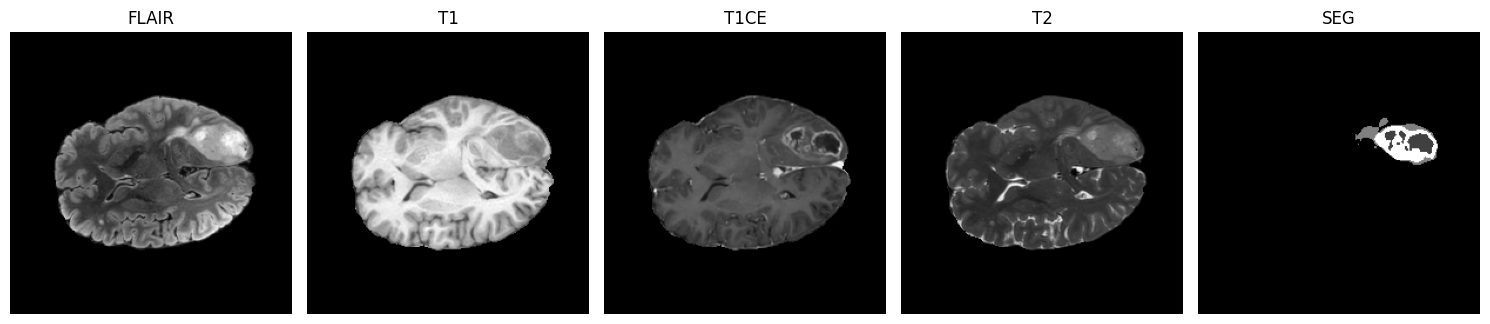

In [ ]:
slice_no = images["flair"].shape[2] // 2

plt.figure(figsize=(15, 5))

for i, modality in enumerate(modalities):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[modality][:, :, slice_no], cmap="gray")
    plt.title(modality.upper())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

print("Folders inside Colab:")
print(os.listdir("/content"))

print("\nFiles inside BraTS2021:")
print(os.listdir("/content/BraTS2021"))

Folders inside Colab:
['.config', 'Patient_00495', 'brats-2021-task1.zip', 'BraTS2021', 'sample_data']

Files inside BraTS2021:
['BraTS2021_Training_Data.tar', 'BraTS2021_00495.tar', 'BraTS2021_00621.tar']


In [ ]:
import os
import tarfile
import shutil

# Check available storage
free_space = shutil.disk_usage("/content").free / (1024**3)

print("Available storage:", round(free_space, 2), "GB")

# Inspect training archive
tar_path = "/content/BraTS2021/BraTS2021_Training_Data.tar"

with tarfile.open(tar_path, "r") as tar:
    print("\nFirst 20 files inside training archive:")

    for i, item in enumerate(tar):
        print(item.name)

        if i == 19:
            break

Available storage: 87.74 GB

First 20 files inside training archive:
.
./.DS_Store
./BraTS2021_00000
./BraTS2021_00000/BraTS2021_00000_flair.nii.gz
./BraTS2021_00000/BraTS2021_00000_seg.nii.gz
./BraTS2021_00000/BraTS2021_00000_t1.nii.gz
./BraTS2021_00000/BraTS2021_00000_t1ce.nii.gz
./BraTS2021_00000/BraTS2021_00000_t2.nii.gz
./BraTS2021_00002
./BraTS2021_00002/BraTS2021_00002_flair.nii.gz
./BraTS2021_00002/BraTS2021_00002_seg.nii.gz
./BraTS2021_00002/BraTS2021_00002_t1.nii.gz
./BraTS2021_00002/BraTS2021_00002_t1ce.nii.gz
./BraTS2021_00002/BraTS2021_00002_t2.nii.gz
./BraTS2021_00003
./BraTS2021_00003/BraTS2021_00003_flair.nii.gz
./BraTS2021_00003/BraTS2021_00003_seg.nii.gz
./BraTS2021_00003/BraTS2021_00003_t1.nii.gz
./BraTS2021_00003/BraTS2021_00003_t1ce.nii.gz
./BraTS2021_00003/BraTS2021_00003_t2.nii.gz


In [ ]:
import zipfile
import os

zip_path = "/content/brats-2021-task1.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print("ZIP file is readable:", True)

    for item in z.infolist():
        if "Training_Data.tar" in item.filename:
            print("Training archive in ZIP:", item.filename)
            print("Expected size (GB):",
                  round(item.file_size / (1024**3), 2))

            extracted_size = os.path.getsize(
                "/content/BraTS2021/BraTS2021_Training_Data.tar"
            )

            print("Current TAR size (GB):",
                  round(extracted_size / (1024**3), 2))

    print("\nChecking ZIP integrity...")
    bad_file = z.testzip()

    if bad_file is None:
        print("ZIP integrity: OK")
    else:
        print("Corrupted ZIP entry:", bad_file)

ZIP file is readable: True
Training archive in ZIP: BraTS2021_Training_Data.tar
Expected size (GB): 12.48
Current TAR size (GB): 12.48

Checking ZIP integrity...
ZIP integrity: OK


In [ ]:
import zipfile
import shutil
import os

zip_path = "/content/brats-2021-task1.zip"
tar_path = "/content/BraTS2021/BraTS2021_Training_Data.tar"
temp_path = tar_path + ".tmp"

with zipfile.ZipFile(zip_path, "r") as z:
    member = next(
        item for item in z.infolist()
        if item.filename.endswith("BraTS2021_Training_Data.tar")
    )

    print("Copying training TAR from ZIP...")

    with z.open(member) as source, open(temp_path, "wb") as destination:
        shutil.copyfileobj(source, destination)

    expected_size = member.file_size
    actual_size = os.path.getsize(temp_path)

    if actual_size != expected_size:
        os.remove(temp_path)
        raise Exception("Size mismatch. The TAR was not replaced.")

    os.replace(temp_path, tar_path)

print("Training TAR restored successfully!")
print("Final size (GB):", round(os.path.getsize(tar_path) / (1024**3), 2))

Copying training TAR from ZIP...
Training TAR restored successfully!
Final size (GB): 12.48


In [ ]:
import tarfile
import re
import os
from collections import defaultdict

TAR_PATH = "/content/BraTS2021/BraTS2021_Training_Data.tar"

# Ensure the file exists before processing
if not os.path.exists(TAR_PATH):
    print(f"[ERROR] File not found at: {TAR_PATH}")
    print("Please make sure to execute cell 6iZqfcOsniMj first to copy/restore the TAR file!")
else:
    EXPECTED_MODALITIES = {"flair", "seg", "t1", "t1ce", "t2"}
    patient_index = defaultdict(set)

    print("Reading training archive...")

    with tarfile.open(TAR_PATH, "r") as tar:
        members = tar.getmembers()

        for member in members:
            match = re.search(
                r"(BraTS2021_\d+)/(BraTS2021_\d+)_(flair|seg|t1|t1ce|t2)\.nii\.gz$",
                member.name
            )

            if match:
                patient_folder, patient_id, modality = match.groups()

                if patient_folder == patient_id:
                    patient_index[patient_id].add(modality)

    complete_patients = sorted([
        patient for patient, modalities in patient_index.items()
        if modalities == EXPECTED_MODALITIES
    ])

    print("\nArchive indexing complete!")
    print("Total archive members:", len(members))
    print("Patients indexed:", len(patient_index))
    print("Complete patients:", len(complete_patients))
    print("Incomplete patients:", len(patient_index) - len(complete_patients))

    print("\nFirst 10 complete patients:")
    print(complete_patients[:10])

Reading training archive...

Archive indexing complete!
Total archive members: 7508
Patients indexed: 1251
Complete patients: 1251
Incomplete patients: 0

First 10 complete patients:
['BraTS2021_00000', 'BraTS2021_00002', 'BraTS2021_00003', 'BraTS2021_00005', 'BraTS2021_00006', 'BraTS2021_00008', 'BraTS2021_00009', 'BraTS2021_00011', 'BraTS2021_00012', 'BraTS2021_00014']


In [ ]:
# ============================================================
# P29: BRAIN TUMOUR SEGMENTATION ON MULTI-MODAL MRI
# GOOGLE COLAB - COMPLETE PRE-TRAINING SETUP
# ============================================================

# -------------------- 1. INSTALLATION -----------------------

!pip -q install nibabel monai

import os
import re
import tarfile
import random
import shutil
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from monai.networks.nets import UNet
from monai.inferers import sliding_window_inference

warnings.filterwarnings("ignore")

# -------------------- 2. ENVIRONMENT ------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    DEVICE = torch.device("cuda:0")
else:
    DEVICE = torch.device("cpu")

print("=" * 60)
print("ENVIRONMENT")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("MONAI:", __import__("monai").__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

# -------------------- 3. PATHS ------------------------------

TAR_PATH = Path(
    "/content/BraTS2021/BraTS2021_Training_Data.tar"
)

PROJECT_DIR = Path("/content/P29_Brain_Tumour_Segmentation")

DATA_DIR = PROJECT_DIR / "data"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
MANIFEST_DIR = PROJECT_DIR / "manifests"
LOG_DIR = PROJECT_DIR / "logs"
RESULTS_DIR = PROJECT_DIR / "results"

VISUALIZATION_DIR = RESULTS_DIR / "visualizations"
PREDICTION_DIR = RESULTS_DIR / "predictions"
UNCERTAINTY_DIR = RESULTS_DIR / "uncertainty_maps"

for folder in [
    DATA_DIR, CHECKPOINT_DIR, MANIFEST_DIR,
    LOG_DIR, VISUALIZATION_DIR,
    PREDICTION_DIR, UNCERTAINTY_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

assert TAR_PATH.exists(), (
    f"Training archive not found: {TAR_PATH}"
)

print("\nProject directories created.")
print("Training archive:", TAR_PATH)
print("Archive size (GB):",
      round(TAR_PATH.stat().st_size / 1024**3, 2))

# -------------------- 4. INDEX TRAINING ARCHIVE --------------

EXPECTED_MODALITIES = {"flair", "seg", "t1", "t1ce", "t2"}

patient_index = defaultdict(dict)

pattern = re.compile(
    r"(BraTS2021_\d+)_(flair|seg|t1|t1ce|t2)\.nii\.gz$"
)

print("\nIndexing training archive...")

with tarfile.open(TAR_PATH, "r:") as tar:
    members = tar.getmembers()

    for member in members:
        if not member.isfile():
            continue

        basename = os.path.basename(member.name)
        match = pattern.fullmatch(basename)

        if match:
            patient_id, modality = match.groups()
            patient_index[patient_id][modality] = member.name

complete_patients = sorted([
    patient_id
    for patient_id, files in patient_index.items()
    if set(files.keys()) == EXPECTED_MODALITIES
])

print("Archive members:", len(members))
print("Patients indexed:", len(patient_index))
print("Complete patients:", len(complete_patients))
print("Incomplete patients:",
      len(patient_index) - len(complete_patients))

assert len(complete_patients) >= 80, (
    "Fewer than 80 complete patients found."
)

# -------------------- 5. FIXED PATIENT SPLIT -----------------

rng = random.Random(SEED)

selected_patients = rng.sample(complete_patients, 80)

train_patients = selected_patients[:52]
val_patients = selected_patients[52:60]
test_patients = selected_patients[60:80]

assert len(train_patients) == 52
assert len(val_patients) == 8
assert len(test_patients) == 20

assert not (set(train_patients) & set(val_patients))
assert not (set(train_patients) & set(test_patients))
assert not (set(val_patients) & set(test_patients))

split_map = {}

for patient in train_patients:
    split_map[patient] = "train"

for patient in val_patients:
    split_map[patient] = "validation"

for patient in test_patients:
    split_map[patient] = "test"

print("\nFIXED DATASET SPLIT")
print("Training:", len(train_patients))
print("Validation:", len(val_patients))
print("Testing:", len(test_patients))
print("Total:", len(selected_patients))

# -------------------- 6. SELECTIVE EXTRACTION ---------------

print("\nExtracting selected patients...")

manifest_rows = []

with tarfile.open(TAR_PATH, "r:") as tar:

    for i, patient_id in enumerate(selected_patients, 1):

        patient_folder = DATA_DIR / patient_id
        patient_folder.mkdir(parents=True, exist_ok=True)

        for modality in sorted(EXPECTED_MODALITIES):

            member_name = patient_index[patient_id][modality]
            member = tar.getmember(member_name)

            output_path = patient_folder / (
                f"{patient_id}_{modality}.nii.gz"
            )

            if not output_path.exists():
                source = tar.extractfile(member)

                if source is None:
                    raise RuntimeError(
                        f"Could not read {member_name}"
                    )

                with source, open(output_path, "wb") as destination:
                    shutil.copyfileobj(source, destination)

            if output_path.stat().st_size == 0:
                raise RuntimeError(
                    f"Empty extracted file: {output_path}"
                )

        manifest_rows.append({
            "patient_id": patient_id,
            "split": split_map[patient_id],
            **{
                modality: str(
                    patient_folder /
                    f"{patient_id}_{modality}.nii.gz"
                )
                for modality in sorted(EXPECTED_MODALITIES)
            }
        })

        if i % 10 == 0:
            print(f"Extracted {i}/80 patients")

manifest_df = pd.DataFrame(manifest_rows)

MANIFEST_PATH = MANIFEST_DIR / "patient_manifest.csv"
manifest_df.to_csv(MANIFEST_PATH, index=False)

print("\nExtraction completed!")
print("Manifest:", MANIFEST_PATH)
print("Total files:", len(selected_patients) * 5)

# -------------------- 7. VERIFY EXTRACTED DATA ---------------

print("\nVerifying extracted files...")

missing_files = []

for _, row in manifest_df.iterrows():
    for modality in EXPECTED_MODALITIES:
        path = Path(row[modality])

        if not path.exists() or path.stat().st_size == 0:
            missing_files.append(str(path))

print("Missing files:", len(missing_files))

assert len(missing_files) == 0, (
    f"Missing files detected: {missing_files[:5]}"
)

# -------------------- 8. GEOMETRY AND LABEL VALIDATION -------

print("\nChecking MRI geometry and segmentation labels...")

geometry_issues = []
invalid_label_patients = []

for _, row in manifest_df.iterrows():

    reference_shape = None
    reference_affine = None

    for modality in ["t1", "t1ce", "t2", "flair", "seg"]:

         nii = nib.load(row[modality])

         if reference_shape is None:
             reference_shape = nii.shape
             reference_affine = nii.affine
         else:
             if nii.shape != reference_shape:
                 geometry_issues.append(
                     (row["patient_id"], modality, "shape mismatch")
                 )

             if not np.allclose(
                 nii.affine, reference_affine, atol=1e-4
             ):
                 geometry_issues.append(
                     (row["patient_id"], modality, "affine mismatch")
                 )

    seg = np.asarray(
        nib.load(row["seg"]).dataobj
    )

    labels = set(np.unique(seg).astype(int).tolist())

    if not labels.issubset({0, 1, 2, 4}):
        invalid_label_patients.append(
            (row["patient_id"], labels)
        )

print("Geometry issues:", len(geometry_issues))
print("Invalid label patients:", len(invalid_label_patients))

assert len(geometry_issues) == 0
assert len(invalid_label_patients) == 0

print("Geometry and label validation passed!")

# -------------------- 9. NORMALIZATION -----------------------

def normalize_mri(volume):

    volume = volume.astype(np.float32)

    mask = volume != 0

    if not np.any(mask):
        return volume

    mean = volume[mask].mean()
    std = volume[mask].std()

    if std < 1e-8:
        volume[mask] = 0.0
    else:
        volume[mask] = (volume[mask] - mean) / std

    return volume


# -------------------- 10. SEGMENTATION REMAPPING -------------

# Original labels:
# 0 = Background
# 1 = Necrotic / non-enhancing tumour core
# 2 = Peritumoral oedema
# 4 = Enhancing tumour

# New labels:
# 0 = Background
# 1 = Necrotic / non-enhancing tumour core
# 2 = Peritumoral oedema
# 3 = Enhancing tumour

def remap_segmentation(seg):

    seg = seg.astype(np.uint8)

    remapped = np.zeros_like(
        seg, dtype=np.uint8
    )

    remapped[seg == 1] = 1
    remapped[seg == 2] = 2
    remapped[seg == 4] = 3

    return remapped


# -------------------- 11. BASE MRI DATASET -------------------

class BraTSDataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

        self.modalities = [
            "t1", "t1ce", "t2", "flair"
        ]

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_channels = []

        for modality in self.modalities:

            volume = nib.load(
                row[modality]
            ).get_fdata(dtype=np.float32)

            volume = normalize_mri(volume)

            image_channels.append(volume)

        image = np.stack(
            image_channels, axis=0
        )

        seg = np.asarray(
            nib.load(row["seg"]).dataobj
        )

        seg = remap_segmentation(seg)

        image = torch.from_numpy(
            image.astype(np.float32)
        )

        label = torch.from_numpy(
            seg.astype(np.int64)
        ).unsqueeze(0)

        return {
            "image": image,
            "label": label,
            "patient_id": row["patient_id"]
        }


# -------------------- 12. SPLIT DATASETS ---------------------

train_df = manifest_df[
    manifest_df["split"] == "train"
].reset_index(drop=True)

val_df = manifest_df[
    manifest_df["split"] == "validation"
].reset_index(drop=True)

test_df = manifest_df[
    manifest_df["split"] == "test"
].reset_index(drop=True)

train_dataset = BraTSDataset(train_df)
val_dataset = BraTSDataset(val_df)
test_dataset = BraTSDataset(test_df)

print("\nDataset sizes:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

# -------------------- 13. TEST ONE MRI VOLUME ----------------

sample = train_dataset[0]

print("\nSample patient:", sample["patient_id"])
print("Image shape:", sample["image"].shape)
print("Label shape:", sample["label"].shape)
print("Image dtype:", sample["image"].dtype)
print("Label dtype:", sample["label"].dtype)
print("Image finite:", torch.isfinite(sample["image"]).all().item())
print("Segmentation classes:",
      torch.unique(sample["label"]).tolist())

assert sample["image"].shape[0] == 4
assert sample["label"].shape[0] == 1
assert torch.isfinite(sample["image"]).all()

# -------------------- 14. PATCH EXTRACTION -------------------

PATCH_SIZE = (96, 96, 96)
PATCHES_PER_PATIENT = 2

def extract_random_patch(image, label, patch_size=PATCH_SIZE):

    _, D, H, W = image.shape

    pd, ph, pw = patch_size

    # Tumour-aware sampling:
    # 2/3 probability: centre around a tumour voxel
    # 1/3 probability: random location

    if np.random.random() < (2 / 3):

        tumour_coords = torch.nonzero(
            label[0] > 0,
            as_tuple=False
        )

        if len(tumour_coords) > 0:

            coord = tumour_coords[
                np.random.randint(len(tumour_coords))
            ]

            cd, ch, cw = coord.tolist()

        else:
            cd = np.random.randint(D)
            ch = np.random.randint(H)
            cw = np.random.randint(W)

    else:

        cd = np.random.randint(D)
        ch = np.random.randint(H)
        cw = np.random.randint(W)

    d_start = max(0, min(cd - pd // 2, D - pd))
    h_start = max(0, min(ch - ph // 2, H - ph))
    w_start = max(0, min(cw - pw // 2, W - pw))

    image_patch = image[
        :,
        d_start:d_start + pd,
        h_start:h_start + ph,
        w_start:w_start + pw
    ]

    label_patch = label[
        :,
        d_start:d_start + pd,
        h_start:h_start + ph,
        w_start:w_start + pw
    ]

    return image_patch, label_patch


# -------------------- 15. PATCH DATASET ----------------------

class BraTSPatchDataset(Dataset):

    def __init__(
        self,
        base_dataset,
        patches_per_patient=PATCHES_PER_PATIENT
    ):

        self.base_dataset = base_dataset
        self.patches_per_patient = patches_per_patient

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):

        sample = self.base_dataset[index]

        image = sample["image"]
        label = sample["label"]

        image_patches = []
        label_patches = []

        for _ in range(self.patches_per_patient):

            image_patch, label_patch = extract_random_patch(
                image, label
            )

            image_patches.append(image_patch)
            label_patches.append(label_patch)

        return {
            "image": torch.stack(image_patches),
            "label": torch.stack(label_patches),
            "patient_id": sample["patient_id"]
        }


train_patch_dataset = BraTSPatchDataset(
    train_dataset,
    patches_per_patient=PATCHES_PER_PATIENT
)

train_loader = DataLoader(
    train_patch_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Validation and test datasets remain full-volume datasets.
val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

# -------------------- 16. DATALOADER TEST --------------------

batch = next(iter(train_loader))

print("\nDATALOADER TEST")
print("Image batch:", batch["image"].shape)
print("Label batch:", batch["label"].shape)
print("Image dtype:", batch["image"].dtype)
print("Label dtype:", batch["label"].dtype)
print("Image finite:",
      torch.isfinite(batch["image"]).all().item())
print("Classes:",
      torch.unique(batch["label"]).tolist())

assert batch["image"].shape == (1, 2, 4, 96, 96, 96)
assert batch["label"].shape == (1, 2, 1, 96, 96, 96)

# -------------------- 17. MODEL CONFIGURATION ----------------

IN_CHANNELS = 4
NUM_CLASSES = 4

LEARNING_RATE = 3e-4
NUM_EPOCHS = 50

BATCH_SIZE = 2

ROI_SIZE = (96, 96, 96)
SW_BATCH_SIZE = 1
SW_OVERLAP = 0.25

model = UNet(
    spatial_dims=3,
    in_channels=IN_CHANNELS,
    out_channels=NUM_CLASSES,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=1,
    norm="BATCH",
    act="RELU"
).to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("\nBASELINE MODEL")
print("Architecture: MONAI 3D U-Net")
print("Parameters:",
      sum(p.numel() for p in model.parameters()))
print("Device:", DEVICE)

# -------------------- 18. FORWARD/BACKWARD TEST --------------

print("\nTesting model forward and backward pass...")

model.train()

test_images = torch.randn(
    1, 4, 96, 96, 96,
    device=DEVICE
)

test_labels = torch.randint(
    0, 4, (1, 96, 96, 96),
    device=DEVICE
)

optimizer.zero_grad(set_to_none=True)

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=torch.cuda.is_available()
):

    outputs = model(test_images)

    loss = criterion(
        outputs,
        test_labels
    )

if torch.cuda.is_available():

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

else:

    loss.backward()
    optimizer.step()

print("Input shape:", test_images.shape)
print("Output shape:", outputs.shape)
print("Test loss:", round(loss.item(), 4))
print("Forward/backward test: SUCCESS")

if torch.cuda.is_available():
    print(
        "Peak GPU memory:",
        round(
            torch.cuda.max_memory_allocated() / 1024**3,
            3
        ),
        "GB"
    )

# -------------------- 19. DICE METRIC HELPER -----------------

def calculate_dice(prediction, target, region="WT"):

    if region == "WT":

        pred_mask = prediction > 0
        target_mask = target > 0

    elif region == "TC":

        pred_mask = (
            (prediction == 1) | (prediction == 3)
        )

        target_mask = (
            (target == 1) | (target == 3)
        )

    else:
        raise ValueError("Region must be WT or TC")

    intersection = (
        pred_mask & target_mask
    ).sum().item()

    denominator = (
        pred_mask.sum().item() +
        target_mask.sum().item()
    )

    if denominator == 0:
        return 1.0

    return (2.0 * intersection) / denominator


# -------------------- 20. FINAL PRE-TRAINING SUMMARY --------

print("\n" + "=" * 60)
print("PRE-TRAINING SETUP COMPLETE")
print("=" * 60)

print("Patients:", len(selected_patients))
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))
print("Patch size:", PATCH_SIZE)
print("Patches per patient:", PATCHES_PER_PATIENT)
print("Training batches per epoch:", len(train_loader))
print("Model parameters:",
      sum(p.numel() for p in model.parameters()))
print("Manifest saved:", MANIFEST_PATH)

print("\nNo model training has started yet.")
print("Ready for the training stage.")

ENVIRONMENT
PyTorch: 2.14.1+cu130
MONAI: 1.6.2
CUDA available: True
Device: cuda:0
GPU: Tesla T4
GPU memory: 14.56 GB

Project directories created.
Training archive: /content/BraTS2021/BraTS2021_Training_Data.tar
Archive size (GB): 12.48

Indexing training archive...
Archive members: 7508
Patients indexed: 1251
Complete patients: 1251
Incomplete patients: 0

FIXED DATASET SPLIT
Training: 52
Validation: 8
Testing: 20
Total: 80

Extracting selected patients...
Extracted 10/80 patients
Extracted 20/80 patients
Extracted 30/80 patients
Extracted 40/80 patients
Extracted 50/80 patients
Extracted 60/80 patients
Extracted 70/80 patients
Extracted 80/80 patients

Extraction completed!
Manifest: /content/P29_Brain_Tumour_Segmentation/manifests/patient_manifest.csv
Total files: 400

Verifying extracted files...
Missing files: 0

Checking MRI geometry and segmentation labels...
Geometry issues: 0
Invalid label patients: 0
Geometry and label validation passed!

Dataset sizes:
Train: 52
Validation:

In [ ]:
# Reset random seeds
SEED = 42

import random
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Reinitialize model with fresh weights
model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128),
    strides=(2, 2, 2),
    num_res_units=1,
    norm="BATCH",
    act="RELU"
).to(DEVICE)

# Fresh optimizer and scaler
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Baseline model reset successfully!")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Optimizer: Fresh Adam")
print("Learning rate:", LEARNING_RATE)
print("Device:", DEVICE)

Baseline model reset successfully!
Parameters: 604320
Optimizer: Fresh Adam
Learning rate: 0.0003
Device: cuda:0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil
import json

# Confirm Google Drive is mounted
DRIVE_ROOT = "/content/drive/MyDrive"

if not os.path.exists(DRIVE_ROOT):
    raise RuntimeError("Google Drive is not mounted. Run drive.mount() first.")

# Create project folder
DRIVE_PROJECT_DIR = os.path.join(
    DRIVE_ROOT, "P29_Brain_Tumour_Segmentation"
)

folders = [
    "checkpoints",
    "logs",
    "results/visualizations",
    "results/predictions",
    "results/uncertainty_maps",
    "manifests"
]

for folder in folders:
    os.makedirs(os.path.join(DRIVE_PROJECT_DIR, folder), exist_ok=True)

# Back up the exact patient split
source_manifest = (
    "/content/P29_Brain_Tumour_Segmentation/"
    "manifests/patient_manifest.csv"
)

if not os.path.exists(source_manifest):
    raise FileNotFoundError("Patient manifest not found!")

destination_manifest = os.path.join(
    DRIVE_PROJECT_DIR, "manifests", "patient_manifest.csv"
)

shutil.copy2(source_manifest, destination_manifest)

print("Google Drive setup successful!")
print("Project directory:", DRIVE_PROJECT_DIR)
print("Patient manifest backed up:", os.path.exists(destination_manifest))
print("Training checkpoints folder:", os.path.join(DRIVE_PROJECT_DIR, "checkpoints"))

Google Drive setup successful!
Project directory: /content/drive/MyDrive/P29_Brain_Tumour_Segmentation
Patient manifest backed up: True
Training checkpoints folder: /content/drive/MyDrive/P29_Brain_Tumour_Segmentation/checkpoints


In [ ]:
import os
import time
import numpy as np
import pandas as pd
import torch
from pathlib import Path

# -------------------- 1. CHECK ENVIRONMENT -------------------

assert torch.cuda.is_available(), "CUDA GPU is not available."
assert len(train_loader) > 0, "Training DataLoader is empty."
assert len(val_loader) > 0, "Validation DataLoader is empty."

# Persistent Google Drive storage
DRIVE_ROOT = Path("/content/drive/MyDrive")

if not DRIVE_ROOT.exists():
    raise RuntimeError(
        "Google Drive is not mounted. Mount Drive before training."
    )

DRIVE_PROJECT_DIR = DRIVE_ROOT / "P29_Brain_Tumour_Segmentation"
DRIVE_CHECKPOINT_DIR = DRIVE_PROJECT_DIR / "checkpoints"
DRIVE_LOG_DIR = DRIVE_PROJECT_DIR / "logs"

DRIVE_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_LOG_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = DRIVE_CHECKPOINT_DIR / "baseline_best.pth"
LATEST_MODEL_PATH = DRIVE_CHECKPOINT_DIR / "baseline_latest.pth"
HISTORY_PATH = DRIVE_LOG_DIR / "baseline_training_history.csv"

print("Training device:", DEVICE)
print("Training patients:", len(train_dataset))
print("Validation patients:", len(val_dataset))
print("Batches per epoch:", len(train_loader))
print("Checkpoint directory:", DRIVE_CHECKPOINT_DIR)

# -------------------- 2. TRAINING CONFIGURATION --------------

NUM_EPOCHS = 50
best_val_score = -1.0

history = []

# -------------------- 3. VALIDATION FUNCTION -----------------

def validate_baseline():

    model.eval()

    wt_scores = []
    tc_scores = []

    with torch.no_grad():

        for batch in val_loader:

            # Keep full MRI volume on CPU.
            # Sliding-window inference sends patches to GPU.
            images = batch["image"].to("cpu")

            labels = (
                batch["label"]
                .squeeze(0)
                .squeeze(0)
                .to("cpu")
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=True
            ):

                outputs = sliding_window_inference(
                    inputs=images,
                    roi_size=ROI_SIZE,
                    sw_batch_size=SW_BATCH_SIZE,
                    predictor=model,
                    overlap=SW_OVERLAP,
                    mode="gaussian",
                    sw_device=DEVICE,
                    device="cpu"
                )

            predictions = torch.argmax(
                outputs, dim=1
            ).squeeze(0)

            wt_dice = calculate_dice(
                predictions, labels, region="WT"
            )

            tc_dice = calculate_dice(
                predictions, labels, region="TC"
            )

            wt_scores.append(wt_dice)
            tc_scores.append(tc_dice)

            del images, labels, outputs, predictions

    mean_wt = float(np.mean(wt_scores))
    mean_tc = float(np.mean(tc_scores))

    return mean_wt, mean_tc


# -------------------- 4. TRAINING LOOP -----------------------

print("\n" + "=" * 65)
print("STARTING BASELINE 3D U-NET TRAINING")
print("=" * 65)

training_start = time.time()

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    model.train()

    running_loss = 0.0

    for batch_idx, batch in enumerate(train_loader):

        # Original shape:
        # Images: [1, 2, 4, 96, 96, 96]
        # Labels: [1, 2, 1, 96, 96, 96]

        # Flatten patient and patch dimensions.
        images = batch["image"].reshape(
            -1, 4, *PATCH_SIZE
        ).to(DEVICE, non_blocking=True)

        labels = batch["label"].reshape(
            -1, *PATCH_SIZE
        ).to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=True
        ):

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        del images, labels, outputs, loss

    epoch_loss = running_loss / len(train_loader)

    # ---------------- VALIDATION ----------------

    val_wt, val_tc = validate_baseline()

    val_score = (val_wt + val_tc) / 2.0

    epoch_time = time.time() - epoch_start

    # ---------------- SAVE HISTORY ----------------

    history.append({
        "epoch": epoch + 1,
        "train_loss": epoch_loss,
        "val_WT_Dice": val_wt,
        "val_TC_Dice": val_tc,
        "val_mean_Dice": val_score,
        "epoch_time_seconds": epoch_time
    })

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        HISTORY_PATH,
        index=False
    )

    # ---------------- SAVE LATEST MODEL ----------------

    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "train_loss": epoch_loss,
        "val_WT_Dice": val_wt,
        "val_TC_Dice": val_tc,
        "val_mean_Dice": val_score,
        "history": history
    }

    torch.save(checkpoint, LATEST_MODEL_PATH)

    # ---------------- SAVE BEST MODEL ----------------

    if val_score > best_val_score:

        best_val_score = val_score

        torch.save(
            checkpoint,
            BEST_MODEL_PATH
        )

        best_status = "BEST MODEL SAVED"

    else:
        best_status = ""

    # ---------------- PRINT PROGRESS ----------------

    print(
        f"\nEpoch [{epoch + 1:02d}/{NUM_EPOCHS}]"
    )

    print(f"Training Loss : {epoch_loss:.4f}")
    print(f"Validation WT : {val_wt:.4f}")
    print(f"Validation TC : {val_tc:.4f}")
    print(f"Mean Dice     : {val_score:.4f}")
    print(f"Best Mean Dice: {best_val_score:.4f}")
    print(f"Time          : {epoch_time / 60:.2f} min")

    if best_status:
        print(best_status)

    print("-" * 50)


# -------------------- 5. TRAINING COMPLETE -------------------

total_time = (time.time() - training_start) / 60

print("\n" + "=" * 65)
print("BASELINE TRAINING COMPLETED")
print("=" * 65)

print(f"Total training time: {total_time:.2f} minutes")
print(f"Best validation mean Dice: {best_val_score:.4f}")

print("\nSaved files:")
print("Best model:", BEST_MODEL_PATH)
print("Latest model:", LATEST_MODEL_PATH)
print("Training history:", HISTORY_PATH)

print("\nThe 20 test patients have NOT been evaluated.")

Training device: cuda:0
Training patients: 52
Validation patients: 8
Batches per epoch: 52
Checkpoint directory: /content/drive/MyDrive/P29_Brain_Tumour_Segmentation/checkpoints

STARTING BASELINE 3D U-NET TRAINING

Epoch [01/50]
Training Loss : 0.9822
Validation WT : 0.3143
Validation TC : 0.1141
Mean Dice     : 0.2142
Best Mean Dice: 0.2142
Time          : 2.02 min
BEST MODEL SAVED
--------------------------------------------------

Epoch [02/50]
Training Loss : 0.4649
Validation WT : 0.4480
Validation TC : 0.2156
Mean Dice     : 0.3318
Best Mean Dice: 0.3318
Time          : 2.05 min
BEST MODEL SAVED
--------------------------------------------------

Epoch [03/50]
Training Loss : 0.2733
Validation WT : 0.3932
Validation TC : 0.1866
Mean Dice     : 0.2899
Best Mean Dice: 0.3318
Time          : 2.07 min
--------------------------------------------------

Epoch [04/50]
Training Loss : 0.2003
Validation WT : 0.4110
Validation TC : 0.1590
Mean Dice     : 0.2850
Best Mean Dice: 0.3318
Tim

In [ ]:
import os
import torch

checkpoint_dir = "/content/drive/MyDrive/P29_Brain_Tumour_Segmentation/checkpoints"

print("Checkpoint folder exists:", os.path.exists(checkpoint_dir))

for filename in ["baseline_best.pth", "baseline_latest.pth"]:
    path = os.path.join(checkpoint_dir, filename)

    if os.path.exists(path):
        print(f"\n{filename}: SAVED")
        print("Size:", round(os.path.getsize(path) / (1024**2), 2), "MB")
    else:
        print(f"\n{filename}: NOT FOUND")

Checkpoint folder exists: False

baseline_best.pth: NOT FOUND

baseline_latest.pth: NOT FOUND


In [ ]:
import os
from pathlib import Path

print("=" * 65)
print("CHECKPOINT RECOVERY DIAGNOSTIC")
print("=" * 65)

# 1. Check Google Drive mount
drive_root = Path("/content/drive/MyDrive")
print("\nGoogle Drive mounted:", drive_root.exists())

# 2. Search likely project locations
search_roots = [
    Path("/content/P29_Brain_Tumour_Segmentation"),
    Path("/content/drive/MyDrive/P29_Brain_Tumour_Segmentation"),
]

# 3. Look for checkpoints and training history
target_names = {
    "baseline_best.pth",
    "baseline_latest.pth",
    "baseline_training_history.csv"
}

found_files = []

for root in search_roots:
    print(f"\nSearching: {root}")

    if not root.exists():
        print("  Folder not found.")
        continue

    for current_dir, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in {
            ".cache", "_pycache_", ".ipynb_checkpoints"
        }]

        for filename in files:
            if filename in target_names:
                path = Path(current_dir) / filename
                size_mb = path.stat().st_size / (1024**2)
                found_files.append(str(path))
                print(f"  FOUND: {path}")
                print(f"  Size: {size_mb:.2f} MB")

# 4. Check common alternative checkpoint locations
print("\nChecking other likely locations...")

for root in [Path("/content"), Path("/content/drive/MyDrive")]:
    if not root.exists():
        continue

    for pattern in ["baseline_best*.pth", "baseline_latest*.pth"]:
        for path in root.glob(pattern):
            print("  FOUND:", path)

# 5. Final status
print("\n" + "=" * 65)

if found_files:
    print("RECOVERY FILES FOUND:", len(found_files))
    print("Do not retrain yet.")
else:
    print("No expected files found in the checked locations.")

print("=" * 65)

CHECKPOINT RECOVERY DIAGNOSTIC

Google Drive mounted: False

Searching: /content/P29_Brain_Tumour_Segmentation
  Folder not found.

Searching: /content/drive/MyDrive/P29_Brain_Tumour_Segmentation
  Folder not found.

Checking other likely locations...

No expected files found in the checked locations.


In [ ]:



from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

root = "/content/drive/MyDrive"

targets = [
    "baseline_best.pth",
    "baseline_latest.pth",
    "baseline_training_history.csv"
]

print("\nSearching Google Drive...")

found = []

for current_dir, dirs, files in os.walk(root):
    dirs[:] = [d for d in dirs if d not in {
        ".Trash", ".cache", ".ipynb_checkpoints"
    }]

    for filename in files:
        if filename in targets:
            path = os.path.join(current_dir, filename)
            size = os.path.getsize(path) / (1024**2)
            found.append(path)
            print(f"\nFOUND: {filename}")
            print(f"Location: {path}")
            print(f"Size: {size:.2f} MB")

print("\n" + "=" * 55)

if found:
    print("Recovery files found:", len(found))
else:
    print("No matching files found in Google Drive.")


Searching Google Drive...

FOUND: baseline_best.pth
Location: /content/drive/MyDrive/P29_Brain_Tumour_Segmentation/checkpoints/baseline_best.pth
Size: 6.99 MB

FOUND: baseline_latest.pth
Location: /content/drive/MyDrive/P29_Brain_Tumour_Segmentation/checkpoints/baseline_latest.pth
Size: 6.99 MB

FOUND: baseline_training_history.csv
Location: /content/drive/MyDrive/P29_Brain_Tumour_Segmentation/logs/baseline_training_history.csv
Size: 0.00 MB

Recovery files found: 3


In [ ]:
import os
import pandas as pd
import torch

PROJECT = "/content/drive/MyDrive/P29_Brain_Tumour_Segmentation"

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

for path in [
    PROJECT + "/manifests/patient_manifest.csv",
    PROJECT + "/checkpoints/baseline_best.pth",
    PROJECT + "/checkpoints/baseline_latest.pth",
    PROJECT + "/logs/baseline_training_history.csv",
    "/content/BraTS2021/BraTS2021_Training_Data.tar"
]:
    print(os.path.basename(path), "->", os.path.exists(path))

manifest_path = PROJECT + "/manifests/patient_manifest.csv"
history_path = PROJECT + "/logs/baseline_training_history.csv"

if os.path.exists(manifest_path):
    manifest = pd.read_csv(manifest_path)
    print("\nManifest shape:", manifest.shape)
    print(manifest.head())

if os.path.exists(history_path):
    history = pd.read_csv(history_path)
    print("\nHistory shape:", history.shape)
    print(history.tail())

GPU: Not available
patient_manifest.csv -> True
baseline_best.pth -> True
baseline_latest.pth -> True
baseline_training_history.csv -> True
BraTS2021_Training_Data.tar -> False

Manifest shape: (80, 7)
        patient_id  split                                              flair  \
0  BraTS2021_00320  train  /content/P29_Brain_Tumour_Segmentation/data/Br...   
1  BraTS2021_00077  train  /content/P29_Brain_Tumour_Segmentation/data/Br...   
2  BraTS2021_00807  train  /content/P29_Brain_Tumour_Segmentation/data/Br...   
3  BraTS2021_00715  train  /content/P29_Brain_Tumour_Segmentation/data/Br...   
4  BraTS2021_00646  train  /content/P29_Brain_Tumour_Segmentation/data/Br...   

                                                 seg  \
0  /content/P29_Brain_Tumour_Segmentation/data/Br...   
1  /content/P29_Brain_Tumour_Segmentation/data/Br...   
2  /content/P29_Brain_Tumour_Segmentation/data/Br...   
3  /content/P29_Brain_Tumour_Segmentation/data/Br...   
4  /content/P29_Brain_Tumour_Segmenta